In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('test_data.csv')

# Select the 5 numerical features used for clustering
features = ['Ride_Distance(km)', 'Ride_Time(min)', 'Customer_Rating', 'Driver_Rating', 'Booking_Value']
X = df[features]

# Replace missing values with the median for each column
X = X.fillna(X.median())

# Check for missing values and display basic info
print("Dataset Info:")
print(X.info())
print("\nMissing Values:")
print(X.isnull().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ride_Distance(km)  6000 non-null   float64
 1   Ride_Time(min)     6000 non-null   int64  
 2   Customer_Rating    6000 non-null   float64
 3   Driver_Rating      6000 non-null   float64
 4   Booking_Value      6000 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 234.5 KB
None

Missing Values:
Ride_Distance(km)    0
Ride_Time(min)       0
Customer_Rating      0
Driver_Rating        0
Booking_Value        0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize the features (Z-score normalization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier handling
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
print(X_scaled_df.head())

   Ride_Distance(km)  Ride_Time(min)  Customer_Rating  Driver_Rating  \
0          -0.956512       -1.329647        -0.698026       0.352955   
1           0.482311       -1.140723         0.337066       0.006723   
2          -1.645733       -0.573951        -0.352995      -1.205089   
3          -1.413047        1.063390        -0.525511      -1.205089   
4           0.158318        0.181745        -0.352995      -0.858857   

   Booking_Value  
0      -1.335565  
1       0.224948  
2      -1.481647  
3      -0.625294  
4       0.223364  


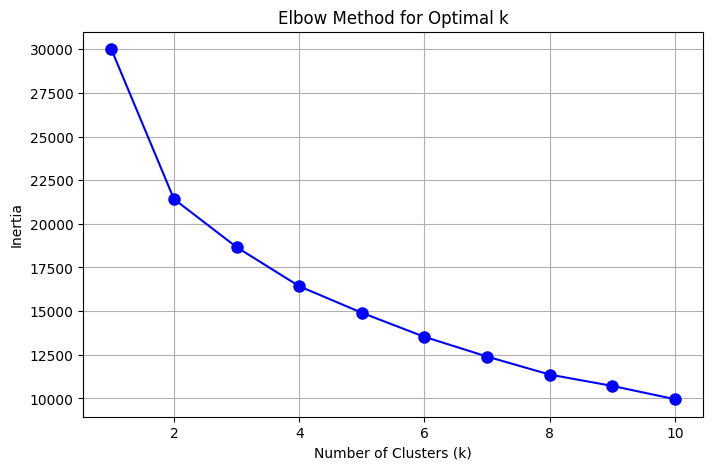

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate inertia for k=1 to 10
inertia = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, 'bo-', markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [ ]:
# Choose k=3 based on elbow curve
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Add cluster labels to the scaled DataFrame
X_scaled_df['Cluster'] = kmeans.labels_

print(f"K-Means applied with k={k}")
print("Cluster counts:")
print(X_scaled_df['Cluster'].value_counts())

K-Means applied with k=3
Cluster counts:
Cluster
1    2528
2    1864
0    1608
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Compute performance metrics
silhouette = silhouette_score(X_scaled, kmeans.labels_)
inertia_val = kmeans.inertia_
db_index = davies_bouldin_score(X_scaled, kmeans.labels_)

print(f"Performance Metrics for k={k}:")
print(f"Silhouette Score: {silhouette:.3f}")
print(f"Inertia: {inertia_val:.2f}")
print(f"Davies-Bouldin Index: {db_index:.3f}")

Performance Metrics for k=3:
Silhouette Score: 0.205
Inertia: 18666.18
Davies-Bouldin Index: 1.641


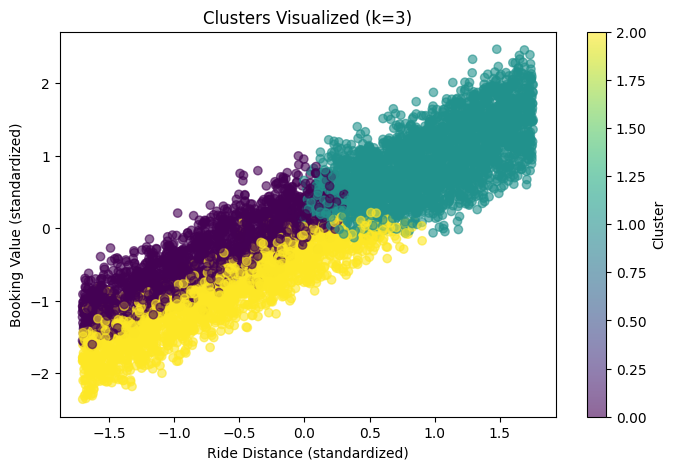

In [ ]:
# Visualize clusters using Ride_Distance(km) vs. Booking_Value
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_scaled_df['Ride_Distance(km)'], X_scaled_df['Booking_Value'],
                      c=X_scaled_df['Cluster'], cmap='viridis', alpha=0.6)
plt.xlabel('Ride Distance (standardized)')
plt.ylabel('Booking Value (standardized)')
plt.title(f'Clusters Visualized (k={k})')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [ ]:
# Analyze cluster characteristics (standardized)
cluster_means = X_scaled_df.groupby('Cluster')[features].mean()

print("Cluster Characteristics (Mean Values, Standardized):")
print(cluster_means.round(4))

# Convert back to original scale
X_original_with_clusters = pd.DataFrame(scaler.inverse_transform(X_scaled_df[features]), columns=features)
X_original_with_clusters['Cluster'] = X_scaled_df['Cluster']
original_means = X_original_with_clusters.groupby('Cluster')[features].mean()

print("\nCluster Characteristics (Mean Values, Original Scale):")
print(original_means.round(2))

Cluster Characteristics (Mean Values, Standardized):
         Ride_Distance(km)  Ride_Time(min)  Customer_Rating  Driver_Rating  \
Cluster                                                                      
0                  -0.7754          0.8963           0.0053        -0.0121   
1                   0.9841          0.0988          -0.0105        -0.0249   
2                  -0.6658         -0.9072           0.0096         0.0442   

         Booking_Value  
Cluster                 
0              -0.3933  
1               0.9527  
2              -0.9528  

Cluster Characteristics (Mean Values, Original Scale):
         Ride_Distance(km)  Ride_Time(min)  Customer_Rating  Driver_Rating  \
Cluster                                                                      
0                     7.81           46.35             4.01           3.99   
1                    19.76           33.68             4.00           3.98   
2                     8.55           17.71             4.01    

In [ ]:
# Compute overall dataset means (original scale)
overall_means = X.mean()

# Calculate percentage differences from overall mean
percent_diff = (original_means - overall_means) / overall_means * 100

print("Percentage Differences from Overall Dataset Mean (%):")
print(percent_diff.round(2))

print("\nOverall Dataset Means (Original Scale):")
print(overall_means.round(2))

Percentage Differences from Overall Dataset Mean (%):
         Ride_Distance(km)  Ride_Time(min)  Customer_Rating  Driver_Rating  \
Cluster                                                                      
0                   -40.27           44.32             0.08          -0.18   
1                    51.11            4.88            -0.15          -0.36   
2                   -34.58          -44.86             0.14           0.64   

         Booking_Value  
Cluster                 
0               -13.52  
1                32.76  
2               -32.76  

Overall Dataset Means (Original Scale):
Ride_Distance(km)     13.07
Ride_Time(min)        32.11
Customer_Rating        4.00
Driver_Rating          4.00
Booking_Value        257.01
dtype: float64
